# code_102 · Label budgets, frozen probes and actual fine-tuning

**Book:** section 20.5. A self-contained representation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_20_GUIDE.md), [run evidence](../CHAPTER_20_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_102).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2102;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2102


<a id="boundaries"></a>
 ## A new-building task with a small signed signal
 Generate 50 buildings × eight 32-sample windows. The first 30 buildings supply unlabeled pretraining inputs and candidate labeled budgets; ten development and ten final buildings are disjoint. Building-specific nuisance amplitudes dominate variance. The independent label is the polarity of a small orthogonal pattern. Pretrain one two-dimensional autoencoder on source inputs only. Three seeded nested building orders allocate 3/10/30 labeled buildings (24/80/240 labels), shared by every method. Every fixed candidate is assessed; development is diagnostic and no final result selects a winner.


,method,labels,mean_Brier,SD_Brier,mean_accuracy,SD_accuracy
0,Absolute filter,24,0.266863,4.120449e-03,0.500000,0.025000
1,Absolute filter,80,0.254924,3.291144e-03,0.491667,0.031458
2,Absolute filter,240,0.249938,3.399350e-17,0.512500,0.000000
3,Fine-tuned AE,24,0.001246,1.867396e-03,1.000000,0.000000
4,Fine-tuned AE,80,0.000139,2.454070e-05,1.000000,0.000000
5,Fine-tuned AE,240,0.000150,3.657538e-05,1.000000,0.000000
6,Frozen AE,24,0.271477,1.531534e-02,0.495833,0.028868
7,Frozen AE,80,0.249466,1.895314e-03,0.529167,0.064145
8,Frozen AE,240,0.248802,3.399350e-17,0.500000,0.000000
9,PCA,24,0.272541,1.668914e-02,0.495833,0.028868


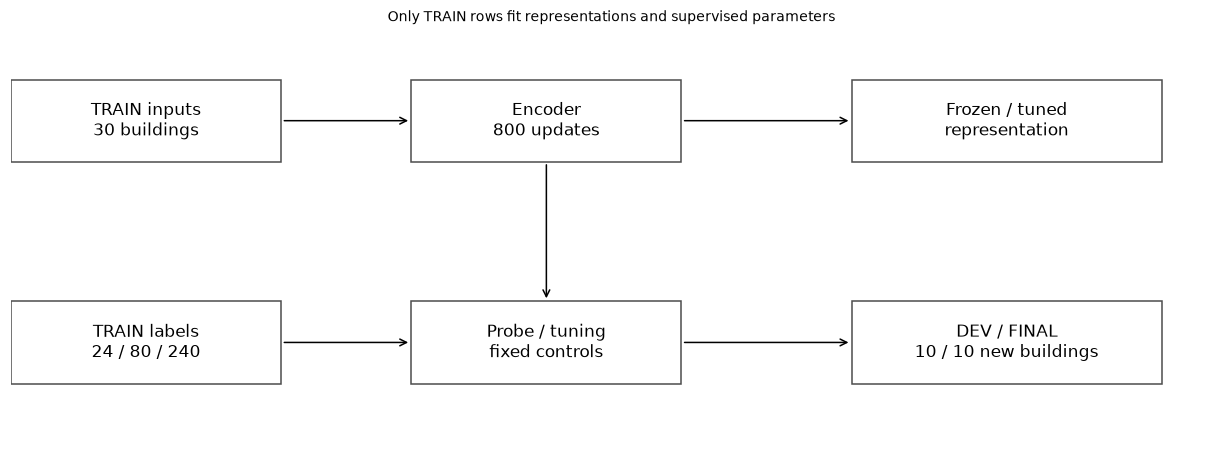

In [2]:
import copy,torch
from torch import nn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss,accuracy_score
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.use_deterministic_algorithms(True);torch.manual_seed(SEED);VERSIONS['torch']=torch.__version__
phase=np.arange(32)*2*np.pi/32;basis=np.linalg.qr(np.column_stack([np.sin(phase),np.cos(phase)]))[0]
pattern=np.zeros(32);pattern[12:16]=[1,-1,1,-1];pattern-=basis@(basis.T@pattern);pattern/=np.linalg.norm(pattern)
building=np.repeat(np.arange(50),8);labels=rng.integers(0,2,400);nuisance=rng.normal(0,1.5,(50,2))[building]+rng.normal(0,.3,(400,2));all_x=nuisance@basis.T+.15*(2*labels-1)[:,None]*pattern+rng.normal(0,.02,(400,32))
source=building<30;development=(building>=30)&(building<40);assessment=building>=40
assert not set(building[source])&set(building[assessment]);assert source.sum()==240 and assessment.sum()==80
center=all_x[source].mean(0);tensor=torch.tensor(all_x-center);encoder=nn.Sequential(nn.Linear(32,8),nn.Tanh(),nn.Linear(8,2),nn.Tanh());decoder=nn.Sequential(nn.Linear(2,8),nn.Tanh(),nn.Linear(8,32));ae=nn.Sequential(encoder,decoder);optimizer=torch.optim.Adam(ae.parameters(),lr=.01,weight_decay=1e-4)
for step in range(800):
    optimizer.zero_grad();loss=torch.mean((ae(tensor[source])-tensor[source])**2);loss.backward();optimizer.step()
with torch.no_grad():latent=encoder(tensor).numpy();ae_mse=float(torch.mean((ae(tensor[assessment])-tensor[assessment])**2))
pca=PCA(2,svd_solver='full').fit(all_x[source]);signed=all_x@pattern
features={'Signed filter':signed[:,None],'Raw window':all_x,'PCA':pca.transform(all_x),'Frozen AE':latent,'Absolute filter':np.abs(signed[:,None])}
# The signed matched filter uses the known diagnostic pattern: a privileged task prior.
standardized={name:StandardScaler().fit(values[source]).transform(values) for name,values in features.items()}
rows=[];drifts=[]
for replicate in range(3):
    order=np.random.default_rng(SEED+100+replicate).permutation(30)
    for count in [3,10,30]:
        admitted=np.isin(building,order[:count]);assert admitted.sum()==count*8 and len(np.unique(labels[admitted]))==2
        for name,values in standardized.items():
            model=LogisticRegression(C=1.,max_iter=1000).fit(values[admitted],labels[admitted]);p=model.predict_proba(values[assessment])[:,1];p_dev=model.predict_proba(values[development])[:,1]
            rows.append({'replicate':replicate,'labels':count*8,'method':name,'final_Brier':float(brier_score_loss(labels[assessment],p)),'final_accuracy':float(accuracy_score(labels[assessment],p>=.5)),'development_Brier':float(brier_score_loss(labels[development],p_dev))})
        torch.manual_seed(SEED+replicate*1000+count);tuned=copy.deepcopy(encoder);head=nn.Linear(2,1);classifier=nn.Sequential(tuned,head);before=torch.cat([p.detach().flatten() for p in tuned.parameters()]);optimizer=torch.optim.Adam(classifier.parameters(),lr=.01,weight_decay=1e-3);criterion=nn.BCEWithLogitsLoss()
        for step in range(400):
            optimizer.zero_grad();loss=criterion(classifier(tensor[admitted]).flatten(),torch.tensor(labels[admitted],dtype=torch.float64));loss.backward();optimizer.step()
        after=torch.cat([p.detach().flatten() for p in tuned.parameters()]);drift=float(torch.linalg.vector_norm(after-before));assert drift>1e-8;drifts.append(drift)
        with torch.no_grad():p=torch.sigmoid(classifier(tensor[assessment]).flatten()).numpy();p_dev=torch.sigmoid(classifier(tensor[development]).flatten()).numpy()
        rows.append({'replicate':replicate,'labels':count*8,'method':'Fine-tuned AE','final_Brier':float(brier_score_loss(labels[assessment],p)),'final_accuracy':float(accuracy_score(labels[assessment],p>=.5)),'development_Brier':float(brier_score_loss(labels[development],p_dev))})
frame=pd.DataFrame(rows);aggregated=[]
for (name,budget),part in frame.groupby(['method','labels'],sort=True):aggregated.append({'method':name,'labels':int(budget),'mean_Brier':float(part.final_Brier.mean()),'SD_Brier':float(part.final_Brier.std(ddof=1)),'mean_accuracy':float(part.final_accuracy.mean()),'SD_accuracy':float(part.final_accuracy.std(ddof=1))})
RESULTS.update(probes=aggregated,individual_runs=rows,encoder_parameter_changes=drifts,final_AE_reconstruction_MSE=ae_mse,final_PCA_reconstruction_MSE=float(np.mean((pca.inverse_transform(pca.transform(all_x[assessment]))-all_x[assessment])**2)),split_buildings=[30,10,10],pretraining_steps=800,fine_tuning_steps=400)
display(pd.DataFrame(aggregated));assert len(rows)==54
fig,ax=plt.subplots(figsize=(11,4));ax.set(xlim=(0,12),ylim=(0,5));ax.axis('off')
boxes=[(0,3.4,2.7,1.,'TRAIN inputs\n30 buildings'),(4,3.4,2.7,1.,'Encoder\n800 updates'),(8.4,3.4,3.1,1.,'Frozen / tuned\nrepresentation'),(0,.7,2.7,1.,'TRAIN labels\n24 / 80 / 240'),(4,.7,2.7,1.,'Probe / tuning\nfixed controls'),(8.4,.7,3.1,1.,'DEV / FINAL\n10 / 10 new buildings')]
from matplotlib.patches import Rectangle
for a,b,w,h,label in boxes:ax.add_patch(Rectangle((a,b),w,h,fill=False,color='.3'));ax.text(a+w/2,b+h/2,label,ha='center',va='center')
for start,end in [((2.7,3.9),(4,3.9)),((6.7,3.9),(8.4,3.9)),((2.7,1.2),(4,1.2)),((6.7,1.2),(8.4,1.2)),((5.35,3.4),(5.35,1.7))]:ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'black'})
ax.set_title('Only TRAIN rows fit representations and supervised parameters');plt.show()


<a id="sufficiency"></a>
 ## Keep the label information visible
 The signed filter has privileged knowledge of the generator pattern; it is a domain-informed comparator, not an equally uninformed learner. Its absolute value removes polarity, illustrating how an invariance can erase the target. All encoder parameters remain frozen for the frozen probe. Fine-tuning copies the pretrained encoder, adds a new head and updates both; nonzero encoder parameter changes are checked. Repeat standard deviations describe these three building orders and head seeds, not population confidence intervals. No field transfer, foundation-model pretraining or causal damage diagnosis is implied.


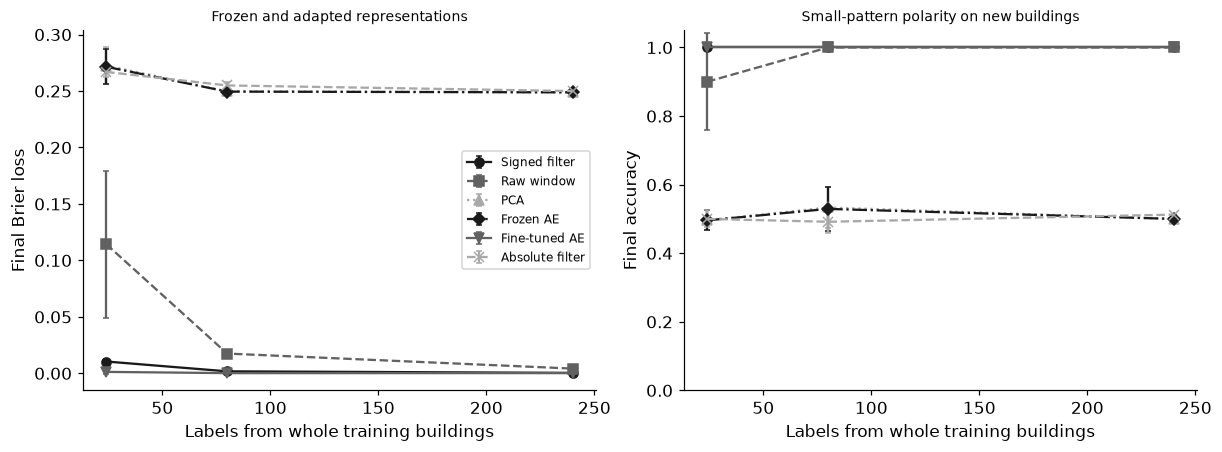

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4));styles=['-','--',':','-.','-','--'];markers=['o','s','^','D','v','x']
for index,name in enumerate(['Signed filter','Raw window','PCA','Frozen AE','Fine-tuned AE','Absolute filter']):
    subset=[r for r in aggregated if r['method']==name];xx=[r['labels'] for r in subset]
    for ax,key,sd in [(axes[0],'mean_Brier','SD_Brier'),(axes[1],'mean_accuracy','SD_accuracy')]:ax.errorbar(xx,[r[key] for r in subset],yerr=[r[sd] for r in subset],linestyle=styles[index],marker=markers[index],color=str(.1+(index%3)*.28),capsize=2,label=name)
axes[0].set(xlabel='Labels from whole training buildings',ylabel='Final Brier loss',title='Frozen and adapted representations');axes[1].set(xlabel='Labels from whole training buildings',ylabel='Final accuracy',ylim=(0,1.05),title='Small-pattern polarity on new buildings');axes[0].legend(fontsize=8);plt.show()
assert all(0<=r['final_Brier']<=1 for r in rows)


In [4]:
summary={'example_id':'code_102','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['whole-building representation assessment', 'frozen linear probes', 'actual encoder fine-tuning', 'invariance can remove task information'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["whole-building representation assessment", "frozen linear probes", "actual encoder fine-tuning", "invariance can remove task information"], "elapsed_seconds": 1.827, "example_id": "code_102", "hardware": "Darwin arm64 CPU", "results": {"encoder_parameter_changes": [5.346457854349838, 5.130658242586451, 5.256875916498482, 5.227090391732023, 5.306906668002642, 5.283706870021827, 5.312715771748238, 5.3325501863703595, 5.118777495833457], "final_AE_reconstruction_MSE": 0.0019195714587805334, "final_PCA_reconstruction_MSE": 0.001120034132266834, "fine_tuning_steps": 400, "individual_runs": [{"development_Brier": 0.010846043789495071, "final_Brier": 0.009548218155985798, "final_accuracy": 1.0, "labels": 24, "method": "Signed filter", "replicate": 0}, {"development_Brier": 0.0863966107693471, "final_Brier": 0.06332780196676599, "final_accuracy": 1.0, "labels": 24, "method": "Raw window", "replicate": 0}, {"development_Brier": 0.26678112384853